In [2]:
import pandas as pd

In [2]:
df = pd.read_csv("SPE_Dataset_ML_Ready_v2.csv")

In [3]:
print(df.columns)

Index(['source.doi', 'source.title', 'source.journal', 'source.year',
       'temperature_C', 'conductivity_S_per_cm', 'transference_number',
       'activation_energy_eV', 'Material_Class', 'host_polymers_clean',
       'salts_clean', 'solvents_clean', 'fillers_clean',
       'Synthesis_Method_Class', 'Tg_C', 'Tm_onset_C', 'Td_C',
       'Voltage_Limit_V', 'Tensile_Strength_MPa', 'Feature_Flexible',
       'Feature_Self_Healing', 'Feature_Flame_Retardant',
       'Feature_Dendrite_Suppression', 'Cell_Class', 'Cathode_Type',
       'Cell_Temperature_C', 'Current_Density_mA_cm2', 'Lifetime_Hours',
       'Is_Stable_Cycling'],
      dtype='object')


In [4]:
df = pd.read_csv("Manual_extraction.csv")

In [5]:
print(df.columns)

Index(['source.doi', 'source.title', 'source.journal', 'source.year',
       'electrolyte_system.category', 'electrolyte_system.host_polymers',
       'electrolyte_system.salts',
       'electrolyte_system.plasticizers_or_solvents',
       'electrolyte_system.fillers_or_frameworks',
       'composition_details.polymer_salt_ratio_text',
       'composition_details.salt_molar_ratios_text',
       'composition_details.filler_loading_text',
       'composition_details.other_key_composition_text',
       'composition_details.special_technique_of_synthesis',
       'structure_and_thermal.amorphous_fraction_text',
       'structure_and_thermal.Tg_C', 'structure_and_thermal.Tm_onset_C',
       'structure_and_thermal.decomposition_onset_C',
       'electrochemical_stability.oxidation_onset_V_vs_Li',
       'electrochemical_stability.stability_window_V',
       'mechanical_properties.tensile_strength_MPa',
       'mechanical_properties.tensile_elongation_percent',
       'mechanical_properties.s

In [3]:
df_llm = pd.read_csv("SPE_Dataset_ML_Ready_v2.csv")
df_manual = pd.read_csv("Manual_extraction.csv")

# 'Manual Column Name' : 'LLM Standardized Column Name'
column_mapping = {
    'electrolyte_system.category': 'Material_Class',
    'electrolyte_system.host_polymers': 'host_polymers_clean',
    'electrolyte_system.salts': 'salts_clean',
    'electrolyte_system.plasticizers_or_solvents': 'solvents_clean',
    'electrolyte_system.fillers_or_frameworks': 'fillers_clean',
    'composition_details.special_technique_of_synthesis': 'Synthesis_Method_Class',
    'structure_and_thermal.Tg_C': 'Tg_C',
    'structure_and_thermal.Tm_onset_C': 'Tm_onset_C',
    'structure_and_thermal.decomposition_onset_C': 'Td_C',
    'electrochemical_stability.stability_window_V': 'Voltage_Limit_V', 
    'mechanical_properties.tensile_strength_MPa': 'Tensile_Strength_MPa',
    'performance_Li_cells.cell_type_text': 'Cell_Class',
    'performance_Li_cells.temperature_C': 'Cell_Temperature_C',
    'performance_Li_cells.current_density_mA_per_cm2': 'Current_Density_mA_cm2',
    'performance_Li_cells.lifetime_hours': 'Lifetime_Hours',
    
    'temperature_C': 'temperature_C',
    'conductivity_S_per_cm': 'conductivity_S_per_cm',
    'transference_number': 'transference_number',
    'activation_energy_eV': 'activation_energy_eV'
}

df_manual_renamed = df_manual.rename(columns=column_mapping)

In [4]:
cols_to_keep = ['source.doi'] + list(column_mapping.values())
available_cols = [col for col in cols_to_keep if col in df_manual_renamed.columns]
df_manual_filtered = df_manual_renamed[available_cols]

In [5]:
aligned_df = pd.merge(
    df_manual_filtered,
    df_llm,
    on='source.doi',
    suffixes=('_GroundTruth', '_LLMOutput'),
    how='inner'
)

reordered_columns = ['source.doi']
for col in column_mapping.values():
    if f"{col}_GroundTruth" in aligned_df.columns and f"{col}_LLMOutput" in aligned_df.columns:
        reordered_columns.extend([f"{col}_GroundTruth", f"{col}_LLMOutput"])

final_aligned_df = aligned_df[reordered_columns]

In [6]:
print(f"Total validation papers matched: {len(final_aligned_df)}")
final_aligned_df.to_csv("Aligned_Validation_Dataset.csv", index=False)

Total validation papers matched: 100


In [7]:
df = pd.read_csv("Aligned_Validation_Dataset.csv")
print(df.columns)

Index(['source.doi', 'Material_Class_GroundTruth', 'Material_Class_LLMOutput',
       'host_polymers_clean_GroundTruth', 'host_polymers_clean_LLMOutput',
       'salts_clean_GroundTruth', 'salts_clean_LLMOutput',
       'solvents_clean_GroundTruth', 'solvents_clean_LLMOutput',
       'fillers_clean_GroundTruth', 'fillers_clean_LLMOutput',
       'Synthesis_Method_Class_GroundTruth',
       'Synthesis_Method_Class_LLMOutput', 'Tg_C_GroundTruth',
       'Tg_C_LLMOutput', 'Tm_onset_C_GroundTruth', 'Tm_onset_C_LLMOutput',
       'Td_C_GroundTruth', 'Td_C_LLMOutput', 'Voltage_Limit_V_GroundTruth',
       'Voltage_Limit_V_LLMOutput', 'Tensile_Strength_MPa_GroundTruth',
       'Tensile_Strength_MPa_LLMOutput', 'Cell_Class_GroundTruth',
       'Cell_Class_LLMOutput', 'Cell_Temperature_C_GroundTruth',
       'Cell_Temperature_C_LLMOutput', 'Current_Density_mA_cm2_GroundTruth',
       'Current_Density_mA_cm2_LLMOutput', 'Lifetime_Hours_GroundTruth',
       'Lifetime_Hours_LLMOutput', 'temperatur

In [8]:
df = df.rename(columns=lambda x: x.replace('_clean', ''))
print("Updated Columns:")
print(df.columns.tolist())

Updated Columns:
['source.doi', 'Material_Class_GroundTruth', 'Material_Class_LLMOutput', 'host_polymers_GroundTruth', 'host_polymers_LLMOutput', 'salts_GroundTruth', 'salts_LLMOutput', 'solvents_GroundTruth', 'solvents_LLMOutput', 'fillers_GroundTruth', 'fillers_LLMOutput', 'Synthesis_Method_Class_GroundTruth', 'Synthesis_Method_Class_LLMOutput', 'Tg_C_GroundTruth', 'Tg_C_LLMOutput', 'Tm_onset_C_GroundTruth', 'Tm_onset_C_LLMOutput', 'Td_C_GroundTruth', 'Td_C_LLMOutput', 'Voltage_Limit_V_GroundTruth', 'Voltage_Limit_V_LLMOutput', 'Tensile_Strength_MPa_GroundTruth', 'Tensile_Strength_MPa_LLMOutput', 'Cell_Class_GroundTruth', 'Cell_Class_LLMOutput', 'Cell_Temperature_C_GroundTruth', 'Cell_Temperature_C_LLMOutput', 'Current_Density_mA_cm2_GroundTruth', 'Current_Density_mA_cm2_LLMOutput', 'Lifetime_Hours_GroundTruth', 'Lifetime_Hours_LLMOutput', 'temperature_C_GroundTruth', 'temperature_C_LLMOutput', 'conductivity_S_per_cm_GroundTruth', 'conductivity_S_per_cm_LLMOutput', 'transference_numb

In [9]:
df.to_csv("Aligned_Validation_Dataset.csv", index=False)
print("\nDataset successfully saved as 'Aligned_Validation_Dataset.csv'")


Dataset successfully saved as 'Aligned_Validation_Dataset.csv'


In [1]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_percentage_error

In [2]:
df = pd.read_csv("Aligned_Validation_Dataset.csv")

In [4]:
# updated to consider the sequence mismatch
df = pd.read_csv("Aligned_Validation_Dataset.csv")

def calculate_token_f1(gt_series, llm_series):
    f1_scores = []
    
    # Drop rows where BOTH are NaN
    valid_mask = ~(gt_series.isna() & llm_series.isna())
    gt_clean = gt_series[valid_mask].fillna("")
    llm_clean = llm_series[valid_mask].fillna("")
    
    for gt_val, llm_val in zip(gt_clean, llm_clean):
        # STRIP brackets and quotes before splitting
        str_gt = str(gt_val).replace('[', '').replace(']', '').replace("'", "").replace('"', "")
        str_llm = str(llm_val).replace('[', '').replace(']', '').replace("'", "").replace('"', "")
        
        # Convert to sets of lowercase, stripped tokens
        gt_tokens = set([x.strip().lower() for x in str_gt.split(',') if x.strip()])
        llm_tokens = set([x.strip().lower() for x in str_llm.split(',') if x.strip()])
        
        # True Positives: Tokens in both GT and LLM
        tp = len(gt_tokens.intersection(llm_tokens))
        # False Positives: Tokens in LLM but not in GT
        fp = len(llm_tokens - gt_tokens)
        # False Negatives: Tokens in GT but not in LLM
        fn = len(gt_tokens - llm_tokens)
        
        if tp + fp + fn == 0:
            f1_scores.append(1.0) # Both empty, perfect match
        else:
            f1 = (2 * tp) / ((2 * tp) + fp + fn)
            f1_scores.append(f1)
            
    return np.mean(f1_scores) if f1_scores else np.nan

categorical_features = ['Material_Class', 'host_polymers', 'salts', 'solvents', 'fillers', 'Synthesis_Method_Class', 'Cell_Class']

print("--- CATEGORICAL FEATURES (Mean Token-Level F1 Score) ---")
for feat in categorical_features:
    col_gt = f"{feat}_GroundTruth"
    col_llm = f"{feat}_LLMOutput"
    if col_gt in df.columns and col_llm in df.columns:
        f1 = calculate_token_f1(df[col_gt], df[col_llm])
        print(f"{feat}: {f1:.4f}")

--- CATEGORICAL FEATURES (Mean Token-Level F1 Score) ---
Material_Class: 0.0100
host_polymers: 0.9700
salts: 0.9917
solvents: 0.9667
fillers: 0.8633
Synthesis_Method_Class: 0.0600
Cell_Class: 0.0000


In [5]:
# --- 1. CHEMICAL LISTS (Token-Level F1) ---
# This uses your existing function which works perfectly for comma-separated chemicals
chemical_lists = ['host_polymers', 'salts', 'solvents', 'fillers']
print("--- CHEMICAL LIST EXTRACTION (Mean Token-Level F1) ---")
for feat in chemical_lists:
    col_gt = f"{feat}_GroundTruth"
    col_llm = f"{feat}_LLMOutput"
    if col_gt in df.columns and col_llm in df.columns:
        f1 = calculate_token_f1(df[col_gt], df[col_llm])
        print(f"{feat}: {f1:.4f}")

# --- 2. SINGLE-LABEL CATEGORIES (Accuracy) ---
# FIXED: We evaluate single string labels using standard Accuracy
from sklearn.metrics import accuracy_score

categorical_features = ['Material_Class', 'Synthesis_Method_Class', 'Cell_Class']
print("\n--- CATEGORICAL CLASSIFICATION (Exact Match Accuracy) ---")
for feat in categorical_features:
    col_gt = f"{feat}_GroundTruth"
    col_llm = f"{feat}_LLMOutput"
    if col_gt in df.columns and col_llm in df.columns:
        # Standardize strings to prevent case/acronym mismatches
        gt_clean = df[col_gt].astype(str).str.strip().str.upper().replace('SOLID POLYMER ELECTROLYTE', 'SPE')
        llm_clean = df[col_llm].astype(str).str.strip().str.upper().replace('SOLID POLYMER ELECTROLYTE', 'SPE')
        
        acc = accuracy_score(gt_clean, llm_clean)
        print(f"{feat}: {acc:.4f}")

# --- 3. CORE CONTINUOUS VARIABLES (Pearson r & MAPE) ---
# FIXED: We ONLY report the core variables that were actively validated by humans.
core_continuous = ['temperature_C', 'conductivity_S_per_cm', 'transference_number', 'activation_energy_eV']
print("\n--- CORE CONTINUOUS VARIABLES (Pearson r | MAPE) ---")
for feat in core_continuous:
    col_gt = f"{feat}_GroundTruth"
    col_llm = f"{feat}_LLMOutput"
    if col_gt in df.columns and col_llm in df.columns:
        is_cond = True if feat == 'conductivity_S_per_cm' else False
        r_val, mape_val = get_continuous_metrics(df[col_gt], df[col_llm], is_conductivity=is_cond)
        
        label = f"{feat} (Log10 applied):" if is_cond else f"{feat}:"
        print(label)
        print(f"   Pearson r : {r_val:.4f}")
        print(f"   MAPE      : {mape_val:.4%}")

--- CHEMICAL LIST EXTRACTION (Mean Token-Level F1) ---
host_polymers: 0.9700
salts: 0.9917
solvents: 0.9667
fillers: 0.8633

--- CATEGORICAL CLASSIFICATION (Exact Match Accuracy) ---
Material_Class: 0.0100
Synthesis_Method_Class: 0.0600
Cell_Class: 0.0000

--- CORE CONTINUOUS VARIABLES (Pearson r | MAPE) ---


/opt/homebrew/Caskroom/miniforge/base/envs/research/lib/python3.10/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
/opt/homebrew/Caskroom/miniforge/base/envs/research/lib/python3.10/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")


NameError: name 'get_continuous_metrics' is not defined

In [6]:
# --- FINAL LLM VALIDATION: CHEMICAL RECIPE EXTRACTION ---
# We strictly evaluate the LLM's ability to extract the core formulation ingredients.

chemical_lists = ['host_polymers', 'salts', 'solvents', 'fillers']
print("--- LLM EXTRACTION FIDELITY (Mean Token-Level F1 Score) ---")

for feat in chemical_lists:
    col_gt = f"{feat}_GroundTruth"
    col_llm = f"{feat}_LLMOutput"
    
    if col_gt in df.columns and col_llm in df.columns:
        f1 = calculate_token_f1(df[col_gt], df[col_llm])
        print(f"{feat.replace('_', ' ').title()}: {f1:.3f}")

--- LLM EXTRACTION FIDELITY (Mean Token-Level F1 Score) ---
Host Polymers: 0.970
Salts: 0.992
Solvents: 0.967
Fillers: 0.863


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

In [3]:
df = pd.read_csv("SPE_Dataset_ML_Ready_v2.csv")
df = pd.read_csv("Manual_extraction.csv")

df_llm = pd.read_csv("SPE_Dataset_ML_Ready_v2.csv")
df_manual = pd.read_csv("Manual_extraction.csv")

# 'Manual Column Name' : 'LLM Standardized Column Name'
column_mapping = {
    'electrolyte_system.category': 'Material_Class',
    'electrolyte_system.host_polymers': 'host_polymers_clean',
    'electrolyte_system.salts': 'salts_clean',
    'electrolyte_system.plasticizers_or_solvents': 'solvents_clean',
    'electrolyte_system.fillers_or_frameworks': 'fillers_clean',
    'composition_details.special_technique_of_synthesis': 'Synthesis_Method_Class',
    'structure_and_thermal.Tg_C': 'Tg_C',
    'structure_and_thermal.Tm_onset_C': 'Tm_onset_C',
    'structure_and_thermal.decomposition_onset_C': 'Td_C',
    'electrochemical_stability.stability_window_V': 'Voltage_Limit_V', 
    'mechanical_properties.tensile_strength_MPa': 'Tensile_Strength_MPa',
    'performance_Li_cells.cell_type_text': 'Cell_Class',
    'performance_Li_cells.temperature_C': 'Cell_Temperature_C',
    'performance_Li_cells.current_density_mA_per_cm2': 'Current_Density_mA_cm2',
    'performance_Li_cells.lifetime_hours': 'Lifetime_Hours',
    
    'temperature_C': 'temperature_C',
    'conductivity_S_per_cm': 'conductivity_S_per_cm',
    'transference_number': 'transference_number',
    'activation_energy_eV': 'activation_energy_eV'
}

df_manual_renamed = df_manual.rename(columns=column_mapping)

In [4]:
cols_to_keep = ['source.doi'] + list(column_mapping.values())
available_cols = [col for col in cols_to_keep if col in df_manual_renamed.columns]
df_manual_filtered = df_manual_renamed[available_cols]


aligned_df = pd.merge(
    df_manual_filtered,
    df_llm,
    on='source.doi',
    suffixes=('_GroundTruth', '_LLMOutput'),
    how='inner'
)

reordered_columns = ['source.doi']
for col in column_mapping.values():
    if f"{col}_GroundTruth" in aligned_df.columns and f"{col}_LLMOutput" in aligned_df.columns:
        reordered_columns.extend([f"{col}_GroundTruth", f"{col}_LLMOutput"])

final_aligned_df = aligned_df[reordered_columns]

print(f"Total validation papers matched: {len(final_aligned_df)}")

Total validation papers matched: 100


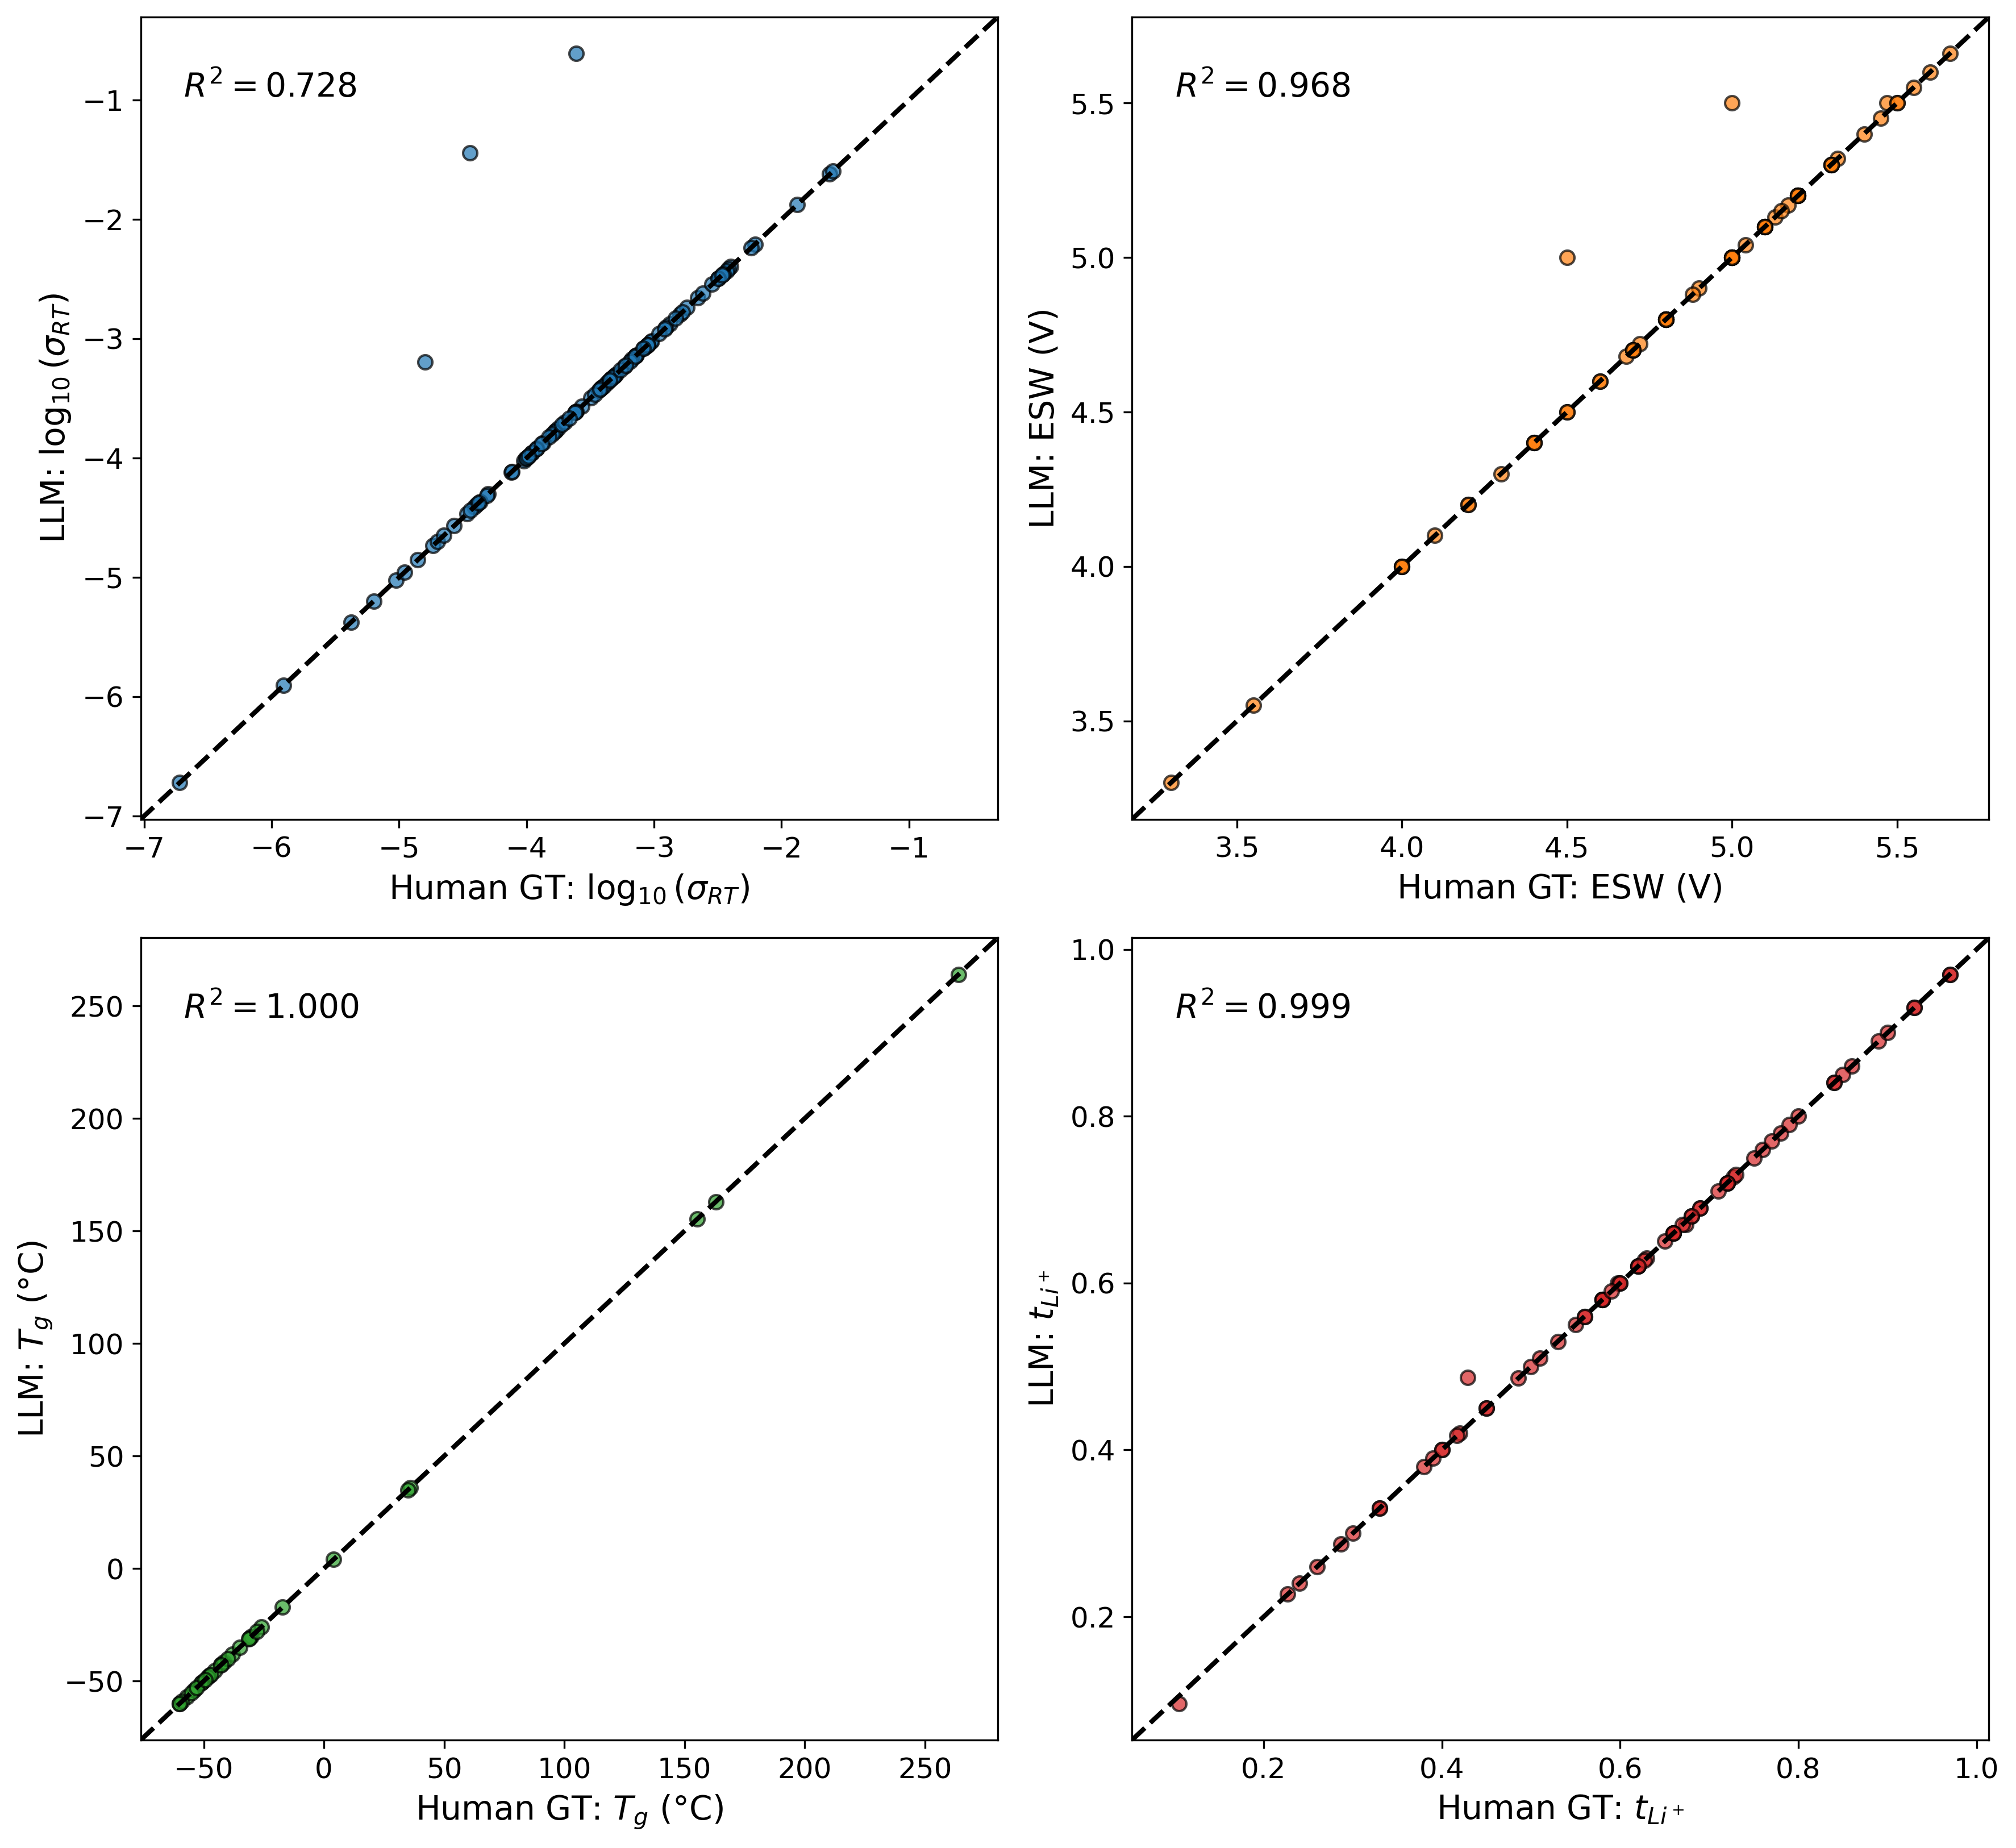

In [20]:
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.dpi': 300,
    'font.family': 'sans-serif'
})

final_aligned_df = pd.read_csv("Aligned_Validation_Dataset.csv")
# We use np.where to prevent log(0) errors if any exact zeros exist in the dataset
final_aligned_df['log10_conductivity_GroundTruth'] = np.log10(
    final_aligned_df['conductivity_S_per_cm_GroundTruth'].where(final_aligned_df['conductivity_S_per_cm_GroundTruth'] > 0)
)
final_aligned_df['log10_conductivity_LLMOutput'] = np.log10(
    final_aligned_df['conductivity_S_per_cm_LLMOutput'].where(final_aligned_df['conductivity_S_per_cm_LLMOutput'] > 0)
)


metrics = [
    {
        'gt_col': 'log10_conductivity_GroundTruth',
        'llm_col': 'log10_conductivity_LLMOutput',
        'xlabel': r'Human GT: $\log_{10}(\sigma_{RT})$',
        'ylabel': r'LLM: $\log_{10}(\sigma_{RT})$',
        'color': '#1f77b4'  # Blue
    },
    {
        'gt_col': 'Voltage_Limit_V_GroundTruth',
        'llm_col': 'Voltage_Limit_V_LLMOutput',
        'xlabel': 'Human GT: ESW (V)',
        'ylabel': 'LLM: ESW (V)',
        'color': '#ff7f0e'  # Orange
    },
    {
        'gt_col': 'Tg_C_GroundTruth',
        'llm_col': 'Tg_C_LLMOutput',
        'xlabel': 'Human GT: $T_g$ (°C)',
        'ylabel': 'LLM: $T_g$ (°C)',
        'color': '#2ca02c'  # Green
    },
    {
        'gt_col': 'transference_number_GroundTruth',
        'llm_col': 'transference_number_LLMOutput',
        'xlabel': 'Human GT: $t_{Li^+}$',
        'ylabel': 'LLM: $t_{Li^+}$',
        'color': '#d62728'  # Red
    }
]


fig, axes = plt.subplots(2, 2, figsize=(12, 11))
axes = axes.flatten()

for idx, metric in enumerate(metrics):
    ax = axes[idx]
    
    # Drop NaNs specifically for this pair to maximize data points per subplot
    temp_df = final_aligned_df[[metric['gt_col'], metric['llm_col']]].dropna()
    
    y_true = temp_df[metric['gt_col']]
    y_pred = temp_df[metric['llm_col']]
    
    # Only plot if we have overlapping data
    if len(y_true) > 1: 
        r2 = r2_score(y_true, y_pred)
        
        ax.scatter(y_true, y_pred, alpha=0.7, edgecolors='k', color=metric['color'])
        
        # Calculate dynamic bounds for the ideal y=x parity line
        min_val = min(y_true.min(), y_pred.min())
        max_val = max(y_true.max(), y_pred.max())
        
        # Add a 5% buffer to the axes limits
        buffer = 0.05 * abs(max_val - min_val)
        min_val -= buffer
        max_val += buffer
        
        ax.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)
        
        # Formatting
        ax.set_xlabel(metric['xlabel'])
        ax.set_ylabel(metric['ylabel'])
        ax.text(0.05, 0.90, f'$R^2 = {r2:.3f}$', transform=ax.transAxes, 
                fontsize=14, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
        ax.set_xlim([min_val, max_val])
        ax.set_ylim([min_val, max_val])

plt.tight_layout()
plt.savefig('Figure_S1_validation_Parity.png', dpi=300, bbox_inches='tight')
plt.show()